# Indian Tourism Analysis – 2025
#  Project Scenario
Scenario:  
A tourism organization wants to analyze tourism activity across India in 2025. They want to understand tourist footfall, domestic vs foreign tourists, tourism revenue, popular purposes of visit, and seasonal patterns so they can identify high-performing states and months and make better tourism decisions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st


# Phase 1 — Load the Dataset

In [2]:
df=pd.read_csv(r"C:\Users\kaith\Downloads\India_Tourism_2025_Processed (1).csv")
df

,State,Month,Date,Month_Number,Domestic Tourists,Foreign Tourists,Total Tourists,Tourism Revenue (INR Crore),Revenue_Per_Tourist_INR,Domestic_Spend_Per_Person_Crore,Foreign_Spend_Per_Person_Crore,Est_Domestic_Revenue_Crore,Est_Foreign_Revenue_Crore,Domestic_Revenue_Percent,Foreign_Revenue_Percent,Annual_Avg_Revenue,Seasonality_Index,Seasonality_Ratio,Purpose of Visit,Growth % (Approx.)
0,Andaman & Nicobar Islands,January,01-01-2025,1,2539148,68865,2608013,53.89,206.632406,0.000019,0.000077,48.615895,5.274105,90.213202,9.786798,38.9750,38.268121,1.382681,Adventure,6.38
1,Andaman & Nicobar Islands,February,01-02-2025,2,4187930,44980,4232910,101.25,239.197148,0.000023,0.000093,97.079321,4.170679,95.880811,4.119189,38.9750,159.781912,2.597819,Business,6.33
2,Andaman & Nicobar Islands,March,01-03-2025,3,149336,99155,248491,5.73,230.591852,0.000010,0.000042,1.567334,4.162666,27.353120,72.646880,38.9750,-85.298268,0.147017,Religious,-4.56
3,Andaman & Nicobar Islands,April,01-04-2025,4,473311,19820,493131,4.92,99.770649,0.000009,0.000036,4.214130,0.705870,85.653042,14.346958,38.9750,-87.376523,0.126235,Medical,-1.42
4,Andaman & Nicobar Islands,May,01-05-2025,5,2475117,35517,2510634,15.32,61.020443,0.000006,0.000023,14.488388,0.831612,94.571725,5.428275,38.9750,-60.692752,0.393072,Business,7.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
427,West Bengal,August,01-08-2025,8,1667393,84612,1752005,30.10,171.803163,0.000015,0.000060,25.021190,5.078810,83.126878,16.873122,36.3975,-17.302013,0.826980,Business,11.60
428,West Bengal,September,01-09-2025,9,4530240,141172,4671412,116.15,248.640026,0.000023,0.000091,103.276705,12.873295,88.916664,11.083336,36.3975,219.115324,3.191153,Business,0.07
429,West Bengal,October,01-10-2025,10,4955630,18550,4974180,52.09,104.720778,0.000010,0.000041,51.321569,0.768431,98.524801,1.475199,36.3975,43.114225,1.431142,Adventure,2.76
430,West Bengal,November,01-11-2025,11,4029483,178343,4207826,67.34,160.035134,0.000014,0.000057,57.211402,10.128598,84.959017,15.040983,36.3975,85.012707,1.850127,Business,13.65


#  Phase 2 - Data Understanding
to understand what data we have.

In [3]:
df.head()

,State,Month,Date,Month_Number,Domestic Tourists,Foreign Tourists,Total Tourists,Tourism Revenue (INR Crore),Revenue_Per_Tourist_INR,Domestic_Spend_Per_Person_Crore,Foreign_Spend_Per_Person_Crore,Est_Domestic_Revenue_Crore,Est_Foreign_Revenue_Crore,Domestic_Revenue_Percent,Foreign_Revenue_Percent,Annual_Avg_Revenue,Seasonality_Index,Seasonality_Ratio,Purpose of Visit,Growth % (Approx.)
0,Andaman & Nicobar Islands,January,01-01-2025,1,2539148,68865,2608013,53.89,206.632406,0.000019,0.000077,48.615895,5.274105,90.213202,9.786798,38.975,38.268121,1.382681,Adventure,6.38
1,Andaman & Nicobar Islands,February,01-02-2025,2,4187930,44980,4232910,101.25,239.197148,0.000023,0.000093,97.079321,4.170679,95.880811,4.119189,38.975,159.781912,2.597819,Business,6.33
2,Andaman & Nicobar Islands,March,01-03-2025,3,149336,99155,248491,5.73,230.591852,0.000010,0.000042,1.567334,4.162666,27.353120,72.646880,38.975,-85.298268,0.147017,Religious,-4.56
3,Andaman & Nicobar Islands,April,01-04-2025,4,473311,19820,493131,4.92,99.770649,0.000009,0.000036,4.214130,0.705870,85.653042,14.346958,38.975,-87.376523,0.126235,Medical,-1.42
4,Andaman & Nicobar Islands,May,01-05-2025,5,2475117,35517,2510634,15.32,61.020443,0.000006,0.000023,14.488388,0.831612,94.571725,5.428275,38.975,-60.692752,0.393072,Business,7.81


In [4]:
df.tail()

,State,Month,Date,Month_Number,Domestic Tourists,Foreign Tourists,Total Tourists,Tourism Revenue (INR Crore),Revenue_Per_Tourist_INR,Domestic_Spend_Per_Person_Crore,Foreign_Spend_Per_Person_Crore,Est_Domestic_Revenue_Crore,Est_Foreign_Revenue_Crore,Domestic_Revenue_Percent,Foreign_Revenue_Percent,Annual_Avg_Revenue,Seasonality_Index,Seasonality_Ratio,Purpose of Visit,Growth % (Approx.)
427,West Bengal,August,01-08-2025,8,1667393,84612,1752005,30.10,171.803163,0.000015,0.000060,25.021190,5.078810,83.126878,16.873122,36.3975,-17.302013,0.826980,Business,11.60
428,West Bengal,September,01-09-2025,9,4530240,141172,4671412,116.15,248.640026,0.000023,0.000091,103.276705,12.873295,88.916664,11.083336,36.3975,219.115324,3.191153,Business,0.07
429,West Bengal,October,01-10-2025,10,4955630,18550,4974180,52.09,104.720778,0.000010,0.000041,51.321569,0.768431,98.524801,1.475199,36.3975,43.114225,1.431142,Adventure,2.76
430,West Bengal,November,01-11-2025,11,4029483,178343,4207826,67.34,160.035134,0.000014,0.000057,57.211402,10.128598,84.959017,15.040983,36.3975,85.012707,1.850127,Business,13.65
431,West Bengal,December,01-12-2025,12,505555,188170,693725,12.87,185.520199,0.000010,0.000041,5.171127,7.698873,40.179696,59.820304,36.3975,-64.640429,0.353596,Adventure,3.24


In [5]:
df.dtypes

State                                  str
Month                                  str
Date                                   str
Month_Number                         int64
Domestic Tourists                    int64
Foreign Tourists                     int64
Total Tourists                       int64
Tourism Revenue (INR Crore)        float64
Revenue_Per_Tourist_INR            float64
Domestic_Spend_Per_Person_Crore    float64
Foreign_Spend_Per_Person_Crore     float64
Est_Domestic_Revenue_Crore         float64
Est_Foreign_Revenue_Crore          float64
Domestic_Revenue_Percent           float64
Foreign_Revenue_Percent            float64
Annual_Avg_Revenue                 float64
Seasonality_Index                  float64
Seasonality_Ratio                  float64
Purpose of Visit                       str
Growth % (Approx.)                 float64
dtype: object

In [6]:
df.shape

(432, 20)

In [7]:
df.columns

Index(['State', 'Month', 'Date', 'Month_Number', 'Domestic Tourists',
       'Foreign Tourists', 'Total Tourists', 'Tourism Revenue (INR Crore)',
       'Revenue_Per_Tourist_INR', 'Domestic_Spend_Per_Person_Crore',
       'Foreign_Spend_Per_Person_Crore', 'Est_Domestic_Revenue_Crore',
       'Est_Foreign_Revenue_Crore', 'Domestic_Revenue_Percent',
       'Foreign_Revenue_Percent', 'Annual_Avg_Revenue', 'Seasonality_Index',
       'Seasonality_Ratio', 'Purpose of Visit', 'Growth % (Approx.)'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 432 entries, 0 to 431
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   State                            432 non-null    str    
 1   Month                            432 non-null    str    
 2   Date                             432 non-null    str    
 3   Month_Number                     432 non-null    int64  
 4   Domestic Tourists                432 non-null    int64  
 5   Foreign Tourists                 432 non-null    int64  
 6   Total Tourists                   432 non-null    int64  
 7   Tourism Revenue (INR Crore)      432 non-null    float64
 8   Revenue_Per_Tourist_INR          432 non-null    float64
 9   Domestic_Spend_Per_Person_Crore  432 non-null    float64
 10  Foreign_Spend_Per_Person_Crore   432 non-null    float64
 11  Est_Domestic_Revenue_Crore       432 non-null    float64
 12  Est_Foreign_Revenue_Crore        

In [9]:
df.describe()

,Month_Number,Domestic Tourists,Foreign Tourists,Total Tourists,Tourism Revenue (INR Crore),Revenue_Per_Tourist_INR,Domestic_Spend_Per_Person_Crore,Foreign_Spend_Per_Person_Crore,Est_Domestic_Revenue_Crore,Est_Foreign_Revenue_Crore,Domestic_Revenue_Percent,Foreign_Revenue_Percent,Annual_Avg_Revenue,Seasonality_Index,Seasonality_Ratio,Growth % (Approx.)
count,432.000000,4.320000e+02,432.000000,4.320000e+02,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,4.320000e+02,432.000000,432.000000
mean,6.500000,2.482521e+06,98793.060185,2.581314e+06,39.530741,154.192631,0.000013,0.000053,34.475053,5.055687,80.586765,19.413235,39.530741,1.532407e-09,1.000000,4.421111
std,3.456055,1.456601e+06,55786.810484,1.458875e+06,27.933304,57.060765,0.000005,0.000021,26.238024,3.528136,17.820559,17.820559,6.461561,6.864483e+01,0.686448,5.684651
min,1.000000,6.096100e+04,1284.000000,1.003880e+05,0.820000,51.440190,0.000003,0.000011,0.187572,0.081498,10.905363,0.142915,26.566667,-9.752888e+01,0.024711,-4.830000
25%,3.750000,1.129177e+06,50432.250000,1.204057e+06,16.487500,104.701499,0.000009,0.000035,13.312388,2.201989,75.045704,7.361409,34.391667,-5.786463e+01,0.421354,-0.567500
50%,6.500000,2.539010e+06,96418.500000,2.622439e+06,33.490000,153.967655,0.000013,0.000051,29.395814,4.397465,86.312436,13.687564,37.550417,-1.272845e+01,0.872716,4.375000
75%,9.250000,3.759052e+06,143211.250000,3.882286e+06,56.642500,204.997422,0.000017,0.000069,51.229540,7.101812,92.638591,24.954296,44.596875,4.253334e+01,1.425333,9.352500
max,12.000000,4.985328e+06,199461.000000,5.164564e+06,118.680000,249.974140,0.000024,0.000098,111.873497,16.900030,99.857085,89.094637,52.737500,2.516158e+02,3.516158,14.910000


# Phase 3 — Data Cleaning

In [10]:
# check missing value
df.isnull().sum()

State                              0
Month                              0
Date                               0
Month_Number                       0
Domestic Tourists                  0
Foreign Tourists                   0
Total Tourists                     0
Tourism Revenue (INR Crore)        0
Revenue_Per_Tourist_INR            0
Domestic_Spend_Per_Person_Crore    0
Foreign_Spend_Per_Person_Crore     0
Est_Domestic_Revenue_Crore         0
Est_Foreign_Revenue_Crore          0
Domestic_Revenue_Percent           0
Foreign_Revenue_Percent            0
Annual_Avg_Revenue                 0
Seasonality_Index                  0
Seasonality_Ratio                  0
Purpose of Visit                   0
Growth % (Approx.)                 0
dtype: int64

In [11]:
# check duplicate
df.duplicated().sum()

np.int64(0)

In [12]:
# check unique values
df["State"].unique()

<ArrowStringArray>
['Andaman & Nicobar Islands',            'Andhra Pradesh',
         'Arunachal Pradesh',                     'Assam',
                     'Bihar',                'Chandigarh',
              'Chhattisgarh',               'Daman & Diu',
                     'Delhi',                       'Goa',
                   'Gujarat',                   'Haryana',
          'Himachal Pradesh',           'Jammu & Kashmir',
                 'Jharkhand',                 'Karnataka',
                    'Kerala',                    'Ladakh',
               'Lakshadweep',            'Madhya Pradesh',
               'Maharashtra',                   'Manipur',
                 'Meghalaya',                   'Mizoram',
                  'Nagaland',                    'Odisha',
                'Puducherry',                    'Punjab',
                 'Rajasthan',                    'Sikkim',
                'Tamil Nadu',                 'Telangana',
                   'Tripura',        

In [13]:
df["Purpose of Visit"].unique()

<ArrowStringArray>
['Adventure', 'Business', 'Religious', 'Medical', 'Leisure']
Length: 5, dtype: str

In [14]:
#Check whether Total Tourists = Domestic + Foreign
print(
    (df["Domestic Tourists"] + df["Foreign Tourists"] == df["Total Tourists"]).all()
)

True


- Check percentages

Domestic + Foreign revenue percentage approximately 100 hona chahiye.

In [15]:
print(
    (df["Domestic_Revenue_Percent"] +
     df["Foreign_Revenue_Percent"]).round(2).eq(100).all()
)

True


- Check negative values

Tourists aur revenue normally negative nahi hone chahiye.

In [16]:
print((df["Domestic Tourists"] < 0).sum())
print((df["Foreign Tourists"] < 0).sum())
print((df["Total Tourists"] < 0).sum())
print((df["Tourism Revenue (INR Crore)"] < 0).sum())

0
0
0
0


- Check Month consistency

Hum check karenge ki January ka Month_Number 1, February 2, etc. hai.

In [17]:
print(df[["Month", "Month_Number"]].drop_duplicates().sort_values("Month_Number"))

        Month  Month_Number
0     January             1
1    February             2
2       March             3
3       April             4
4         May             5
5        June             6
6        July             7
7      August             8
8   September             9
9     October            10
10   November            11
11   December            12


In [18]:
#Dataset ko CSV file se Python DataFrame me load kiya.
df=pd.read_csv(r"C:\Users\kaith\Downloads\India_Tourism_2025_Processed (1).csv")

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

In [19]:
print((df["Date"].dt.month == df["Month_Number"]).all())

True


In [20]:
df=pd.read_csv(r"C:\Users\kaith\Downloads\India_Tourism_2025_Processed (1).csv")

print(df[["Date", "Month", "Month_Number"]].head(15))

          Date      Month  Month_Number
0   01-01-2025    January             1
1   01-02-2025   February             2
2   01-03-2025      March             3
3   01-04-2025      April             4
4   01-05-2025        May             5
5   01-06-2025       June             6
6   01-07-2025       July             7
7   01-08-2025     August             8
8   01-09-2025  September             9
9   01-10-2025    October            10
10  01-11-2025   November            11
11  01-12-2025   December            12
12  01-01-2025    January             1
13  01-02-2025   February             2
14  01-03-2025      March             3


In [21]:
#Check impossible percentage values
#revenue percentages ideally 0–100 ke beech hone chahiye.

print(df[
    (df["Domestic_Revenue_Percent"] < 0) |
    (df["Domestic_Revenue_Percent"] > 100)
])

Empty DataFrame
Columns: [State, Month, Date, Month_Number, Domestic Tourists, Foreign Tourists, Total Tourists, Tourism Revenue (INR Crore), Revenue_Per_Tourist_INR, Domestic_Spend_Per_Person_Crore, Foreign_Spend_Per_Person_Crore, Est_Domestic_Revenue_Crore, Est_Foreign_Revenue_Crore, Domestic_Revenue_Percent, Foreign_Revenue_Percent, Annual_Avg_Revenue, Seasonality_Index, Seasonality_Ratio, Purpose of Visit, Growth % (Approx.)]
Index: []


In [22]:
# Validate that foreign revenue percentage is within 0–100
print(df[
    (df["Foreign_Revenue_Percent"] < 0) |
    (df["Foreign_Revenue_Percent"] > 100)
])

Empty DataFrame
Columns: [State, Month, Date, Month_Number, Domestic Tourists, Foreign Tourists, Total Tourists, Tourism Revenue (INR Crore), Revenue_Per_Tourist_INR, Domestic_Spend_Per_Person_Crore, Foreign_Spend_Per_Person_Crore, Est_Domestic_Revenue_Crore, Est_Foreign_Revenue_Crore, Domestic_Revenue_Percent, Foreign_Revenue_Percent, Annual_Avg_Revenue, Seasonality_Index, Seasonality_Ratio, Purpose of Visit, Growth % (Approx.)]
Index: []


In [23]:
#Check Seasonality values
print(df[["Seasonality_Index", "Seasonality_Ratio"]].describe())

       Seasonality_Index  Seasonality_Ratio
count       4.320000e+02         432.000000
mean        1.532407e-09           1.000000
std         6.864483e+01           0.686448
min        -9.752888e+01           0.024711
25%        -5.786463e+01           0.421354
50%        -1.272845e+01           0.872716
75%         4.253334e+01           1.425333
max         2.516158e+02           3.516158


In [24]:
#Check exact column names
print(df.columns.tolist())

['State', 'Month', 'Date', 'Month_Number', 'Domestic Tourists', 'Foreign Tourists', 'Total Tourists', 'Tourism Revenue (INR Crore)', 'Revenue_Per_Tourist_INR', 'Domestic_Spend_Per_Person_Crore', 'Foreign_Spend_Per_Person_Crore', 'Est_Domestic_Revenue_Crore', 'Est_Foreign_Revenue_Crore', 'Domestic_Revenue_Percent', 'Foreign_Revenue_Percent', 'Annual_Avg_Revenue', 'Seasonality_Index', 'Seasonality_Ratio', 'Purpose of Visit', 'Growth % (Approx.)']


# Phase 4 — Data Transformation

In [25]:
# Convert Date column to DateTime format for date-based analysis
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

In [26]:
# Calculate total tourists for each month
monthly = df.groupby("Month_Number")["Total Tourists"].sum()

In [27]:
#convert month into proper order 
# Define correct month order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Convert Month into ordered categorical data
df["Month"] = pd.Categorical(
    df["Month"],
    categories=month_order,
    ordered=True
)

In [28]:
# Check the month values and their defined order
print(df["Month"].cat.categories)

Index(['January', 'February', 'March', 'April', 'May', 'June', 'July',
       'August', 'September', 'October', 'November', 'December'],
      dtype='str')


In [29]:
# create tourist percentage
# Calculate domestic tourist percentage
df["Domestic_Tourist_Percent"] = (
    df["Domestic Tourists"] / df["Total Tourists"] * 100
)

# Calculate foreign tourist percentage
df["Foreign_Tourist_Percent"] = (
    df["Foreign Tourists"] / df["Total Tourists"] * 100
)

In [30]:
# Check the calculated domestic and foreign tourist percentages
print(df[[
    "Domestic Tourists",
    "Foreign Tourists",
    "Total Tourists",
    "Domestic_Tourist_Percent",
    "Foreign_Tourist_Percent"
]].head())

   Domestic Tourists  Foreign Tourists  Total Tourists  \
0            2539148             68865         2608013   
1            4187930             44980         4232910   
2             149336             99155          248491   
3             473311             19820          493131   
4            2475117             35517         2510634   

   Domestic_Tourist_Percent  Foreign_Tourist_Percent  
0                 97.359484                 2.640516  
1                 98.937374                 1.062626  
2                 60.097146                39.902854  
3                 95.980784                 4.019216  
4                 98.585337                 1.414663  


In [31]:
# Rename growth column for easier use
df.rename(
    columns={"Growth % (Approx.)": "Growth_Percent"},
    inplace=True
)

In [32]:
df["Growth_Percent"]

0       6.38
1       6.33
2      -4.56
3      -1.42
4       7.81
       ...  
427    11.60
428     0.07
429     2.76
430    13.65
431     3.24
Name: Growth_Percent, Length: 432, dtype: float64

In [33]:
#Rename the tourism revenue column for easier use
df.rename(
    columns={"Tourism Revenue (INR Crore)": "Tourism_Revenue_Crore"},
    inplace=True
)

In [34]:
df["Tourism_Revenue_Crore"]

0       53.89
1      101.25
2        5.73
3        4.92
4       15.32
        ...  
427     30.10
428    116.15
429     52.09
430     67.34
431     12.87
Name: Tourism_Revenue_Crore, Length: 432, dtype: float64

Convert the Date column into datetime format and extract the year.

In [35]:
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
print(df[["Date", "Year"]].head())

        Date  Year
0 2025-01-01  2025
1 2025-02-01  2025
2 2025-03-01  2025
3 2025-04-01  2025
4 2025-05-01  2025


# Phase 5 - EDA / Analysis

1. Which states receive the highest number of tourists?

In [36]:
# Calculate total tourists by state
state_tourists = df.groupby("State")["Total Tourists"].sum()

# Show top 10 states
print(state_tourists.sort_values(ascending=False).head(10))

State
Delhi                        42857769
Odisha                       41590468
Tamil Nadu                   38143698
Daman & Diu                  36245107
Chandigarh                   35417635
Andaman & Nicobar Islands    35187230
Bihar                        34349558
Haryana                      34204495
Andhra Pradesh               33969348
Assam                        33806602
Name: Total Tourists, dtype: int64


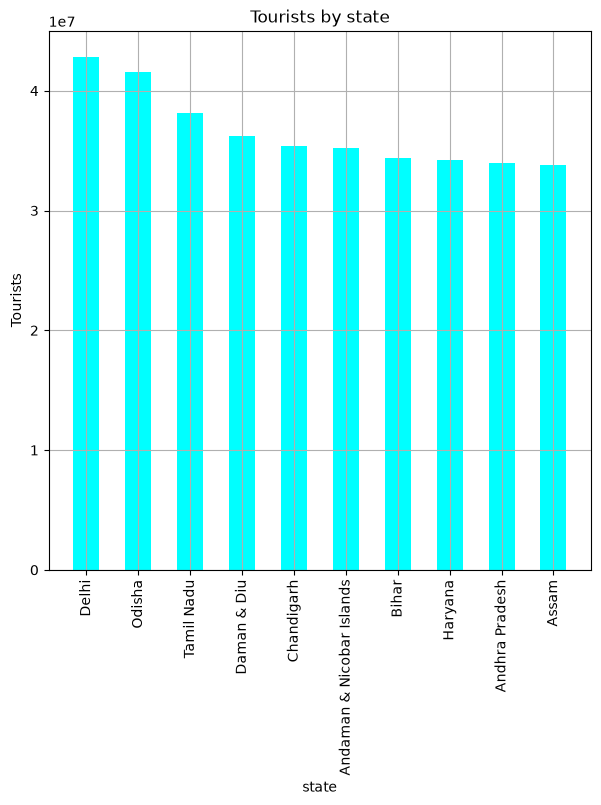

In [37]:
#bar chart
state=["Delhi","Odisha","Tamil Nadu","Daman & Diu","Chandigarh","Andaman & Nicobar Islands","Bihar","Haryana","Andhra Pradesh","Assam"]
Tourists=[ 42857769, 41590468, 38143698, 36245107, 35417635, 35187230,34349558,34204495, 33969348,33806602]
plt.figure(figsize=(7,7))
plt.bar(state,Tourists, color="cyan",width=0.5)
plt.title("Tourists by state")
plt.xlabel("state")
plt.ylabel("Tourists")
plt.grid()
plt.xticks(rotation=90)
plt.show()

2. Which states generate the highest tourism revenue?

In [38]:
# Calculate total revenue by state
state_revenue = df.groupby("State")["Tourism_Revenue_Crore"].sum()

# Show top 10 states
print(state_revenue.sort_values(ascending=False).head(10))

State
Haryana           632.85
Tamil Nadu        630.22
Delhi             606.46
Odisha            605.57
Maharashtra       568.28
Chandigarh        567.84
Assam             565.38
Bihar             560.50
Andhra Pradesh    540.78
Rajasthan         533.29
Name: Tourism_Revenue_Crore, dtype: float64


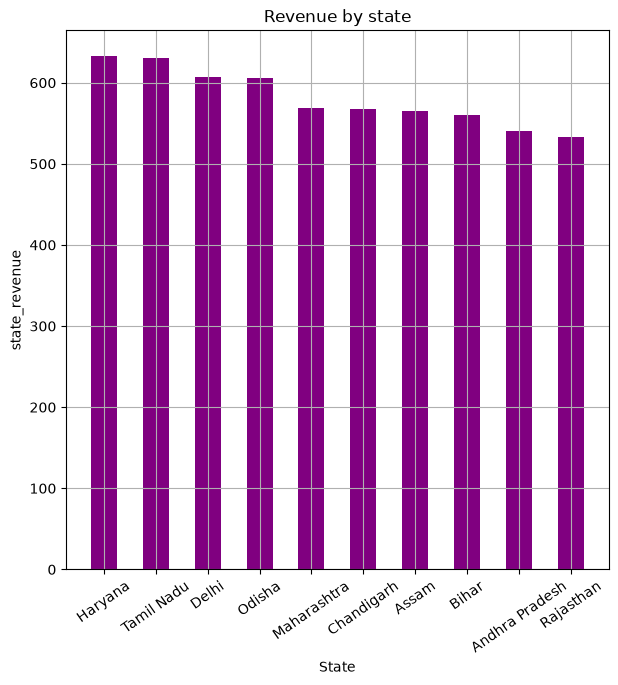

In [39]:
#bar chart
State=["Haryana","Tamil Nadu","Delhi","Odisha","Maharashtra","Chandigarh","Assam","Bihar","Andhra Pradesh","Rajasthan"]
state_revenue=[632.85, 630.22, 606.46, 605.57,568.28, 567.84,565.38,560.50,540.78,533.29]
plt.figure(figsize=(7,7))
plt.bar(State,state_revenue, color="purple",width=0.5)
plt.title("Revenue by state")
plt.xlabel("State")
plt.ylabel("state_revenue")
plt.grid()
plt.xticks(rotation=35)
plt.show()



3. What is the ratio of domestic vs foreign tourists?
- percentage, which is easier to explain:

In [40]:
print(df[["Domestic_Tourist_Percent", "Foreign_Tourist_Percent"]].mean())

Domestic_Tourist_Percent    92.905063
Foreign_Tourist_Percent      7.094937
dtype: float64


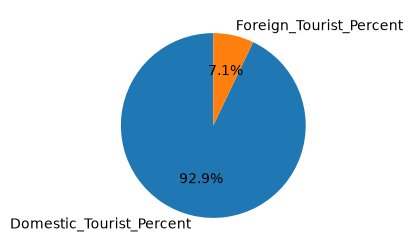

In [41]:
#pie chart
Tourists_Type=["Domestic_Tourist_Percent","Foreign_Tourist_Percent "]
Tourists_percentage=[92.905063,7.094937]
plt.figure(figsize=(3,3))
plt.pie(Tourists_percentage, labels=Tourists_Type,autopct="%1.1f%%",startangle=90)
plt.show()




4. Which months have the highest tourism activity?

In [42]:
# Calculate total tourists by month
monthly = df.groupby("Month")["Total Tourists"].sum()

# Show months with highest tourists
print(monthly.sort_values(ascending=False))

Month
November     111819178
August        99471877
January       98416175
October       97720796
June          97659404
July          96703481
September     96413518
March         93180197
May           90414370
April         87559817
December      78698291
February      67070591
Name: Total Tourists, dtype: int64


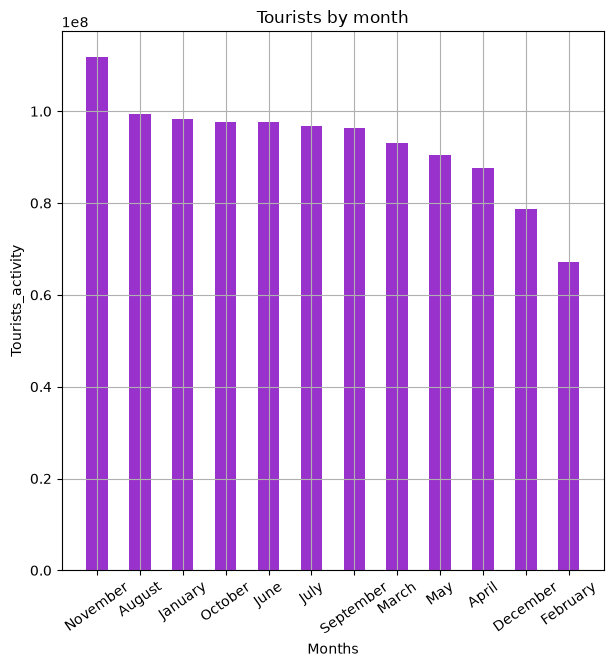

In [43]:
#bar chart
Months=["November","August","January","October","June","July","September","March","May","April","December","February"]
Tourists_activity=[111819178,99471877,98416175,97720796,97659404,96703481,96413518,93180197,90414370,87559817,78698291,67070591]
plt.figure(figsize=(7,7))
plt.bar(Months,Tourists_activity, color="darkorchid",width=0.5)
plt.title("Tourists by month")
plt.xlabel("Months")
plt.ylabel("Tourists_activity")
plt.grid()
plt.xticks(rotation=35)
plt.show()

5. Which states have the highest revenue per tourist?

In [44]:
# Calculate revenue per tourist by state
revenue_per_tourist = (
    df.groupby("State")["Tourism_Revenue_Crore"].sum()
    / df.groupby("State")["Total Tourists"].sum()
)

print(revenue_per_tourist.sort_values(ascending=False).head(10))

State
Haryana          0.000019
Maharashtra      0.000018
Sikkim           0.000017
Uttar Pradesh    0.000017
Nagaland         0.000017
Karnataka        0.000017
Tripura          0.000017
Assam            0.000017
Rajasthan        0.000017
Puducherry       0.000017
dtype: float64


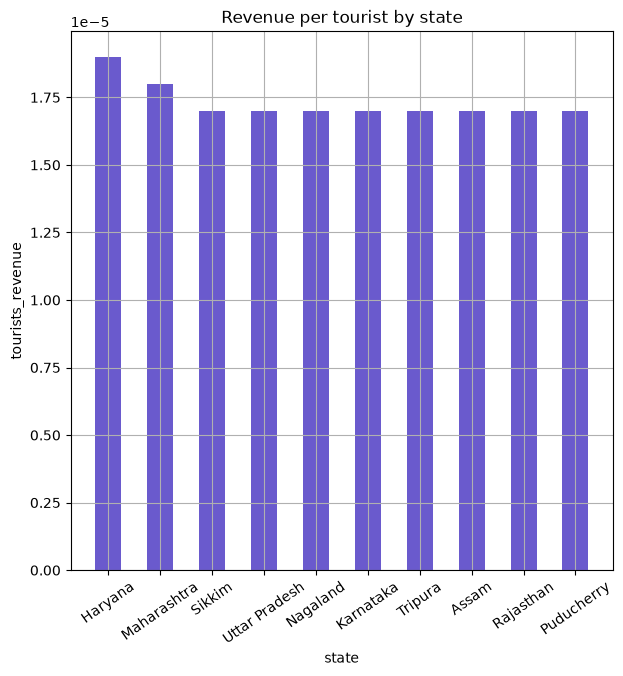

In [45]:
#bar chart
state=["Haryana","Maharashtra","Sikkim","Uttar Pradesh","Nagaland","Karnataka","Tripura","Assam","Rajasthan","Puducherry"]
tourists_revenue=[0.000019,0.000018,0.000017,0.000017,0.000017,0.000017,0.000017,0.000017,0.000017,0.000017]
plt.figure(figsize=(7,7))
plt.bar(state,tourists_revenue, color="slateblue",width=0.5)
plt.title("Revenue per tourist by state")
plt.xlabel("state")
plt.ylabel("tourists_revenue")
plt.grid()
plt.xticks(rotation=35)
plt.show()


6. What is the seasonal tourism pattern?

In [46]:
# Calculate total tourists by month name
print(df.groupby("Month")["Total Tourists"].sum())

Month
January       98416175
February      67070591
March         93180197
April         87559817
May           90414370
June          97659404
July          96703481
August        99471877
September     96413518
October       97720796
November     111819178
December      78698291
Name: Total Tourists, dtype: int64


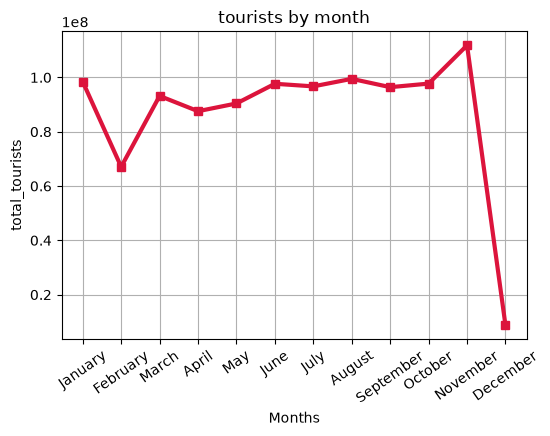

In [47]:
#line chart
Months=["January","February","March","April","May","June","July","August","September","October","November","December"]
total_tourists=[98416175,67070591,93180197,87559817,90414370,97659404,96703481,99471877,96413518,97720796,111819178,8698291]
plt.figure(figsize=(6,4)) # Sets the figure size
plt.plot(Months,total_tourists,color="crimson",marker="s",linewidth=3,linestyle="-")
plt.title("tourists by month")
plt.xlabel("Months") 
plt.ylabel("total_tourists") 
plt.grid()
plt.xticks(rotation=35)
plt.show() 

7. How does tourist volume relate to revenue?

In [48]:
# Check correlation between tourists and revenue
correlation = df["Total Tourists"].corr(df["Tourism_Revenue_Crore"])

print("Correlation:", correlation)

Correlation: 0.7830867060033806


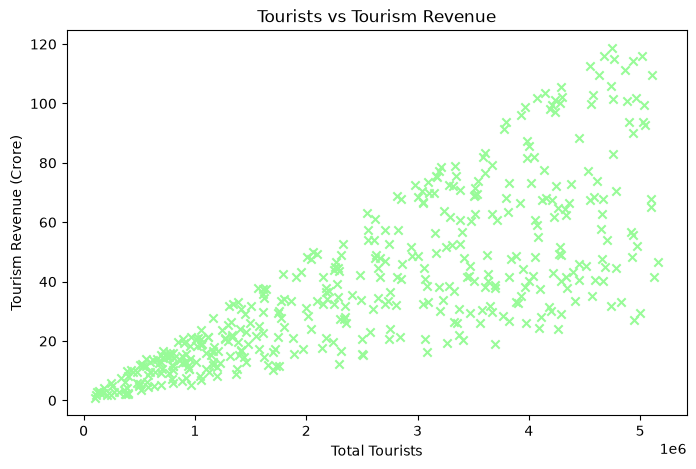

In [49]:
#scatter plot
plt.figure(figsize=(8,5))

plt.scatter(
    df["Total Tourists"],
    df["Tourism_Revenue_Crore"],
    color="palegreen",
    marker="x"
)

plt.xlabel("Total Tourists")
plt.ylabel("Tourism Revenue (Crore)")
plt.title("Tourists vs Tourism Revenue")

plt.show()


8. Which states/months are the strongest tourism performers?
- For states:

In [50]:
# Find top-performing states
top_states = df.groupby("State")[["Total Tourists", "Tourism_Revenue_Crore"]].sum()

print(top_states.sort_values("Total Tourists", ascending=False).head(10))

                           Total Tourists  Tourism_Revenue_Crore
State                                                           
Delhi                            42857769                 606.46
Odisha                           41590468                 605.57
Tamil Nadu                       38143698                 630.22
Daman & Diu                      36245107                 449.77
Chandigarh                       35417635                 567.84
Andaman & Nicobar Islands        35187230                 467.70
Bihar                            34349558                 560.50
Haryana                          34204495                 632.85
Andhra Pradesh                   33969348                 540.78
Assam                            33806602                 565.38


- For months:

In [51]:
# Find top-performing months
top_months = df.groupby("Month")[["Total Tourists", "Tourism_Revenue_Crore"]].sum()

print(top_months.sort_values("Total Tourists", ascending=False))

           Total Tourists  Tourism_Revenue_Crore
Month                                           
November        111819178                1806.17
August           99471877                1439.75
January          98416175                1486.72
October          97720796                1434.45
June             97659404                1532.89
July             96703481                1506.48
September        96413518                1593.00
March            93180197                1426.58
May              90414370                1326.78
April            87559817                1209.24
December         78698291                1209.66
February         67070591                1105.56


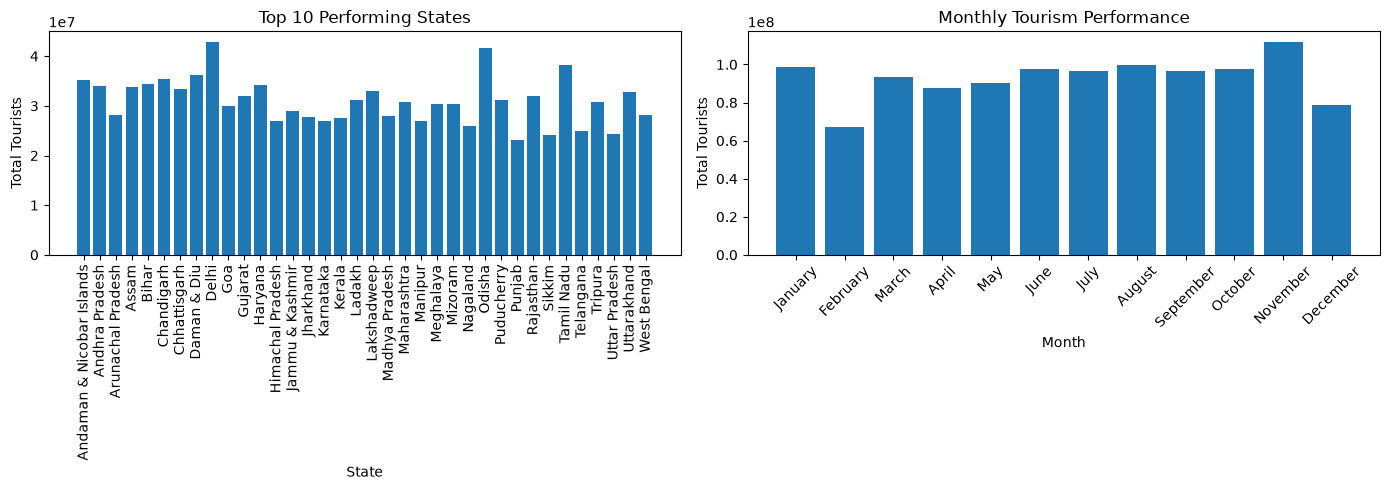

In [52]:
#subplot
plt.figure(figsize=(14,5))

# State-wise
plt.subplot(1,2,1)
plt.bar(top_states.index, top_states["Total Tourists"])
plt.title("Top 10 Performing States")
plt.xlabel("State")
plt.ylabel("Total Tourists")
plt.xticks(rotation=90)

# Month-wise
plt.subplot(1,2,2)
plt.bar(top_months.index, top_months["Total Tourists"])
plt.title("Monthly Tourism Performance")
plt.xlabel("Month")
plt.ylabel("Total Tourists")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Phase 6- Insight

1. Top tourist states

In [53]:
top_states = df.groupby("State")["Total Tourists"].sum().sort_values(ascending=False).head(10)

print(top_states)

State
Delhi                        42857769
Odisha                       41590468
Tamil Nadu                   38143698
Daman & Diu                  36245107
Chandigarh                   35417635
Andaman & Nicobar Islands    35187230
Bihar                        34349558
Haryana                      34204495
Andhra Pradesh               33969348
Assam                        33806602
Name: Total Tourists, dtype: int64


Delhi receives the highest number of tourists, followed by Odisha and Tamil Nadu.

2. Top revenue states

In [54]:
top_revenue = df.groupby("State")["Tourism_Revenue_Crore"].sum().sort_values(ascending=False).head(10)

print(top_revenue)

State
Haryana           632.85
Tamil Nadu        630.22
Delhi             606.46
Odisha            605.57
Maharashtra       568.28
Chandigarh        567.84
Assam             565.38
Bihar             560.50
Andhra Pradesh    540.78
Rajasthan         533.29
Name: Tourism_Revenue_Crore, dtype: float64


Haryana generates the highest tourism revenue, followed by Tamil Nadu and Delhi, indicating strong tourism revenue generation in these states.

#3. Domestic vs Foreign percentage
- Domestic tourists account for 92.9%, while foreign tourists account for 7.1%, showing that domestic tourism is the major contributor.

In [55]:
#4. Highest tourism months
monthly = df.groupby("Month")["Total Tourists"].sum().sort_values(ascending=False)

print(monthly)

Month
November     111819178
August        99471877
January       98416175
October       97720796
June          97659404
July          96703481
September     96413518
March         93180197
May           90414370
April         87559817
December      78698291
February      67070591
Name: Total Tourists, dtype: int64


December has the highest tourism activity, making it one of the peak tourism months.

In [56]:
#5. Highest revenue per tourist
revenue_per_tourist = (
    df.groupby("State")["Tourism_Revenue_Crore"].sum()
    / df.groupby("State")["Total Tourists"].sum()
)

print(revenue_per_tourist.sort_values(ascending=False).head(10))

State
Haryana          0.000019
Maharashtra      0.000018
Sikkim           0.000017
Uttar Pradesh    0.000017
Nagaland         0.000017
Karnataka        0.000017
Tripura          0.000017
Assam            0.000017
Rajasthan        0.000017
Puducherry       0.000017
dtype: float64


Haryana has the highest revenue per tourist, followed by Maharashtra and Sikkim.

In [57]:
#6. Seasonal tourism pattern
seasonal = df.groupby("Month")["Total Tourists"].sum()

print(seasonal)

Month
January       98416175
February      67070591
March         93180197
April         87559817
May           90414370
June          97659404
July          96703481
August        99471877
September     96413518
October       97720796
November     111819178
December      78698291
Name: Total Tourists, dtype: int64


November has the highest tourism activity, while December shows the lowest. Tourism activity remains relatively high from June to November.

In [58]:
#Tourist volume vs Revenue
correlation = df["Total Tourists"].corr(df["Tourism_Revenue_Crore"])

print(correlation)

0.7830867060033806


Tourist volume and tourism revenue show a strong positive relationship, with a correlation of 0.78.

In [59]:
#Strongest states/months
top_states = df.groupby("State")[["Total Tourists", "Tourism_Revenue_Crore"]].sum()

print(top_states.sort_values("Total Tourists", ascending=False).head(10))


top_months = df.groupby("Month")[["Total Tourists", "Tourism_Revenue_Crore"]].sum()

print(top_months.sort_values("Total Tourists", ascending=False))


                           Total Tourists  Tourism_Revenue_Crore
State                                                           
Delhi                            42857769                 606.46
Odisha                           41590468                 605.57
Tamil Nadu                       38143698                 630.22
Daman & Diu                      36245107                 449.77
Chandigarh                       35417635                 567.84
Andaman & Nicobar Islands        35187230                 467.70
Bihar                            34349558                 560.50
Haryana                          34204495                 632.85
Andhra Pradesh                   33969348                 540.78
Assam                            33806602                 565.38
           Total Tourists  Tourism_Revenue_Crore
Month                                           
November        111819178                1806.17
August           99471877                1439.75
January          9841617

#States:
- Delhi is the strongest tourism-performing state, followed by Odisha and Tamil Nadu, based on total tourist arrivals.

#Months:
- November is the strongest-performing month, followed by August and June, based on tourist activity.